# 04 - Évaluation et comparaison des modèles

## Objectif

Ce notebook a pour objectif d'évaluer les performances des modèles de détection de fraude entraînés dans le notebook précédent.

Les modèles étudiés sont :

- Régression logistique.
- Random Forest.

## Méthodologie

L'évaluation se déroule en deux étapes :

1. Comparaison des modèles sur l'ensemble de validation.
2. Évaluation finale du modèle sélectionné sur l'ensemble de test.

## Indicateurs d'évaluation

- Accuracy : proportion de prédictions correctes.
- Precision : proportion de fraudes prédites qui sont réellement frauduleuses.
- Recall : proportion de fraudes réellement détectées.
- F1-score : équilibre entre Precision et Recall.
- ROC-AUC : capacité du modèle à distinguer les deux classes.
- PR-AUC : qualité de la détection des fraudes en tenant compte du déséquilibre des classes.

Une attention particulière sera accordée au Recall et à la Precision.

Importation des bibliothèques

In [44]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    roc_curve
)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


Chargement des modèles et des données

In [45]:
# Recherche du répertoire principal
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "notebooks").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Dossier du projet introuvable.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Répertoires
MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Chargement des modèles
logistic_model = joblib.load(
    MODEL_DIR / "logistic_regression.pkl"
)

random_forest_model = joblib.load(
    MODEL_DIR / "random_forest.pkl"
)

# Chargement des données
valid = pd.read_parquet(DATA_DIR / "valid.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")

# Variables explicatives
features = [
    "transaction_type",
    "amount",
    "heure",
    "tranche_horaire",
    "type_jour",
    "orig_type",
    "dest_type"
]

X_valid = valid[features]
y_valid = valid["is_fraud"]

X_test = test[features]
y_test = test["is_fraud"]

print("Modèles et données chargés avec succès.")

print("Validation :", X_valid.shape)
print("Test :", X_test.shape)

Modèles et données chargés avec succès.
Validation : (45896, 7)
Test : (44216, 7)


Génération des prédictions sur la validation

In [46]:
# Probabilités de fraude
logistic_proba = logistic_model.predict_proba(X_valid)[:, 1]

rf_proba = random_forest_model.predict_proba(X_valid)[:, 1]

# Prédictions avec le seuil standard de 0.5
logistic_pred = (logistic_proba >= 0.5).astype(int)

rf_pred = (rf_proba >= 0.5).astype(int)

print("Prédictions générées sur l'ensemble de validation.")

Prédictions générées sur l'ensemble de validation.


Comparaison des performances

In [47]:
def evaluate_model(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba)
    }


results = pd.DataFrame({
    "Régression logistique": evaluate_model(
        y_valid, logistic_pred, logistic_proba
    ),
    "Random Forest": evaluate_model(
        y_valid, rf_pred, rf_proba
    )
}).T

display(results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Régression logistique,0.7969,0.0491,0.8351,0.0927,0.9143,0.1927
Random Forest,0.9549,0.1571,0.6035,0.2493,0.9199,0.4591


Comparaison graphique

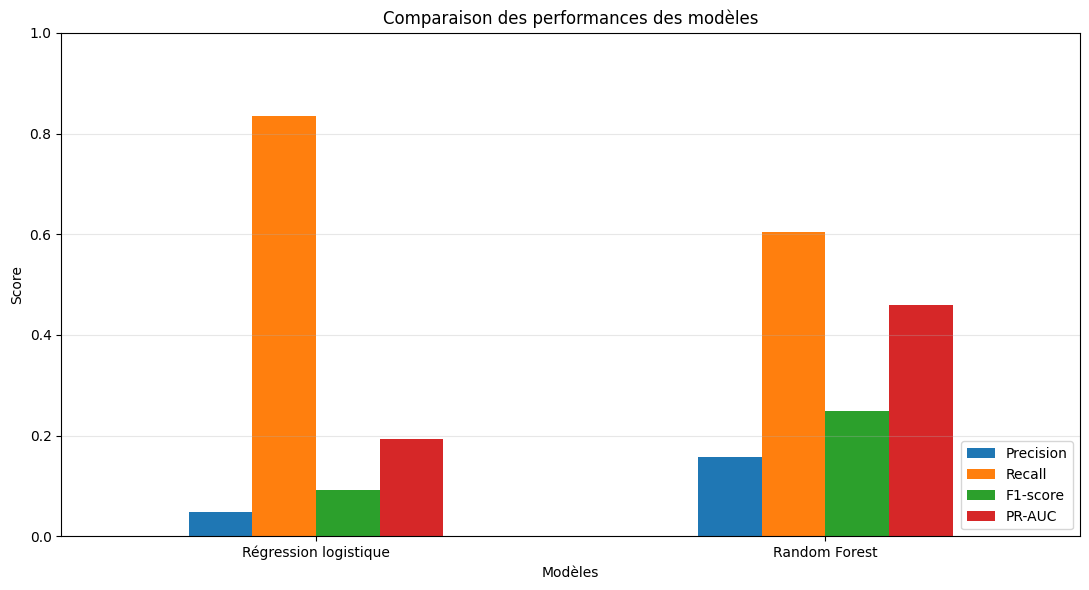

In [48]:
results[["Precision", "Recall", "F1-score", "PR-AUC"]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparaison des performances des modèles")
plt.ylabel("Score")
plt.xlabel("Modèles")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Analyse des courbes Precision-Recall

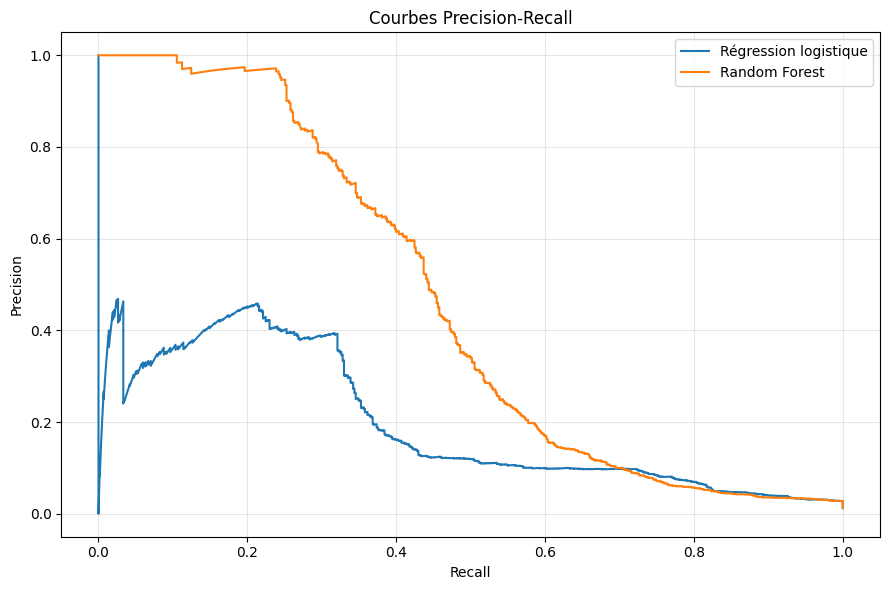

In [49]:
# Courbes Precision-Recall
precision_log, recall_log, _ = precision_recall_curve(
    y_valid, logistic_proba
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_valid, rf_proba
)

plt.figure(figsize=(9, 6))

plt.plot(
    recall_log,
    precision_log,
    label="Régression logistique"
)

plt.plot(
    recall_rf,
    precision_rf,
    label="Random Forest"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbes Precision-Recall")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Recherche d'un seuil de décision adapté

In [50]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (rf_proba >= threshold).astype(int)

    threshold_results.append({
        "Seuil": threshold,
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_valid, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Seuil,Precision,Recall,F1-score
0,0.10,0.0331,0.9561,0.0639
1,0.15,0.0354,0.9053,0.0681
2,0.20,0.0444,0.8509,0.0844
3,0.25,0.0563,0.8018,0.1052
4,0.30,0.0723,0.7491,0.1319
5,0.35,0.0921,0.7158,0.1632
6,0.40,0.1127,0.6825,0.1934
7,0.45,0.1349,0.6456,0.2232
8,0.50,0.1571,0.6035,0.2493
9,0.55,0.1944,0.5877,0.2922


Nous visualisons ensuite l'évolution des indicateurs :

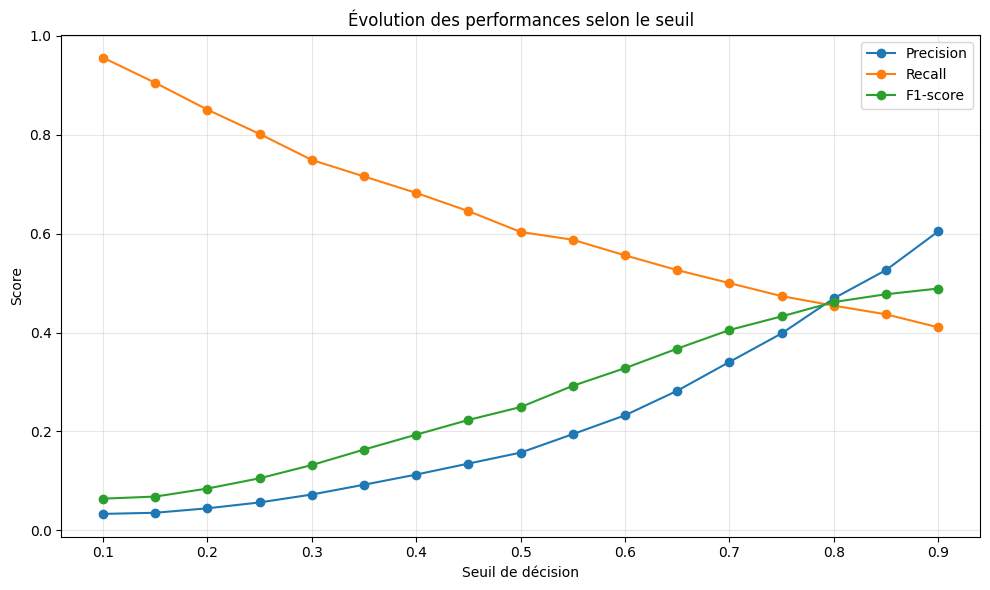

In [51]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Seuil"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Seuil"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Seuil"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Évolution des performances selon le seuil")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Sélection du modèle et du seuil

In [52]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1-score"].idxmax()
]

selected_threshold = float(best_threshold_row["Seuil"])

selected_model = random_forest_model

print("Modèle sélectionné : Random Forest")
print(f"Seuil retenu : {selected_threshold:.2f}")

print("\nPerformances sur la validation :")
print(best_threshold_row)

Modèle sélectionné : Random Forest
Seuil retenu : 0.90

Performances sur la validation :
Seuil        0.900000
Precision    0.604651
Recall       0.410526
F1-score     0.489028
Name: 16, dtype: float64


Évaluation finale sur le test

In [53]:
# Probabilités de fraude sur le test
test_proba = selected_model.predict_proba(X_test)[:, 1]

# Prédictions avec le seuil retenu
test_pred = (test_proba >= selected_threshold).astype(int)

# Calcul des performances
final_results = evaluate_model(
    y_test,
    test_pred,
    test_proba
)

final_results = pd.DataFrame(
    [final_results],
    index=["Random Forest"]
)

display(final_results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Random Forest,0.9485,0.9141,0.4712,0.6219,0.9215,0.711


Matrice de confusion

,Prédit : normal,Prédit : fraude
Réel : normal,40063,176
Réel : fraude,2103,1874


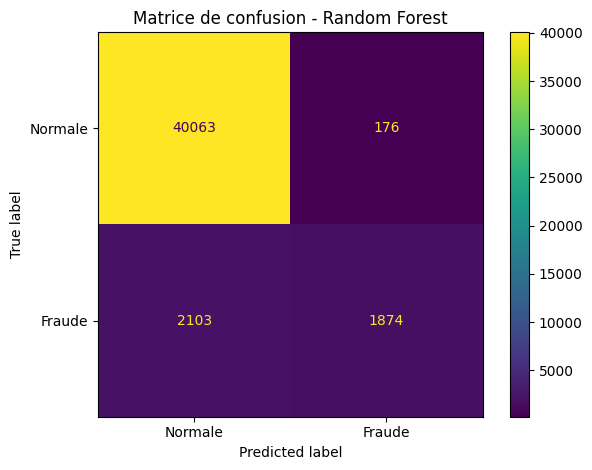

In [54]:
cm = confusion_matrix(y_test, test_pred)

display(pd.DataFrame(
    cm,
    index=["Réel : normal", "Réel : fraude"],
    columns=["Prédit : normal", "Prédit : fraude"]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normale", "Fraude"]
).plot(values_format="d")

plt.title("Matrice de confusion - Random Forest")
plt.tight_layout()
plt.show()

Rapport de classification

In [55]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Transaction normale", "Transaction frauduleuse"],
        zero_division=0
    )
)

                         precision    recall  f1-score   support

    Transaction normale       0.95      1.00      0.97     40239
Transaction frauduleuse       0.91      0.47      0.62      3977

               accuracy                           0.95     44216
              macro avg       0.93      0.73      0.80     44216
           weighted avg       0.95      0.95      0.94     44216



Comparaison avec le système de détection existant

In [56]:
# Comparaison du Random Forest avec le système de détection existant

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Prédictions du système existant
baseline_pred = test["is_flagged_fraud"].astype(int)

# Calcul des métriques du système existant
baseline_results = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0)
}

# Récupération des résultats du Random Forest
rf_results = {
    metric: final_results.loc["Random Forest", metric]
    for metric in baseline_results
}

# Tableau comparatif
comparison = pd.DataFrame({
    "Système existant": baseline_results,
    "Random Forest": rf_results
})

print("COMPARAISON DES DEUX SYSTÈMES")
display(comparison.round(4))

COMPARAISON DES DEUX SYSTÈMES


,Système existant,Random Forest
Accuracy,0.9103,0.9485
Precision,1.0000,0.9141
Recall,0.0033,0.4712
F1-score,0.0065,0.6219


Sauvegarde des résultats

In [57]:
# Création du dossier de résultats
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Sauvegarde des performances
final_results.to_csv(
    RESULTS_DIR / "performances_finales.csv"
)

results.to_csv(
    RESULTS_DIR / "comparaison_validation.csv"
)

threshold_df.to_csv(
    RESULTS_DIR / "analyse_seuils.csv",
    index=False
)

# Sauvegarde des prédictions finales
test_predictions = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred": test_pred,
    "fraud_probability": test_proba,
    "existing_flag": baseline_pred.values
})

test_predictions.to_parquet(
    RESULTS_DIR / "predictions_test.parquet",
    index=False
)

# Sauvegarde du seuil sélectionné
joblib.dump(
    selected_threshold,
    MODEL_DIR / "selected_threshold.pkl"
)

print("Résultats sauvegardés avec succès.")

Résultats sauvegardés avec succès.


# Conclusion

Ce notebook a permis d'évaluer les modèles de détection de fraude développés précédemment.

La comparaison entre la régression logistique et le Random Forest a été réalisée sur l'ensemble de validation.

Un seuil de décision a ensuite été sélectionné à partir des résultats de validation, avant de procéder à l'évaluation finale sur l'ensemble de test.

Les performances obtenues permettent d'apprécier la capacité du modèle à détecter les transactions frauduleuses tout en limitant les fausses alertes.

Les résultats seront interprétés dans le notebook suivant afin de dégager les principales caractéristiques associées aux fraudes et de formuler des recommandations opérationnelles.

Les performances doivent être interprétées en tenant compte du caractère synthétique de PaySim, de l'échantillonnage réalisé et des différences de distribution observées entre les périodes.